بررسی مقادیر گمشده:
 diagnoses.ajcc_pathologic_stage    0
diagnoses.age_at_diagnosis         0
A1BG_RNA                           0
dtype: int64

آمار توصیفی بیان ژن (A1BG_RNA):
count    178.000000
mean       0.233713
std        0.168150
min        0.000000
25%        0.124454
50%        0.204569
75%        0.275511
max        1.168421
Name: A1BG_RNA, dtype: float64


C:\Users\Mahdieh\AppData\Local\Temp\ipykernel_32716\3553183600.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=plot_df, x='diagnoses.ajcc_pathologic_stage', ax=axes[0, 0], palette='viridis')
C:\Users\Mahdieh\AppData\Local\Temp\ipykernel_32716\3553183600.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='diagnoses.ajcc_pathologic_stage', y='A1BG_RNA', ax=axes[1, 0], palette='Set2')


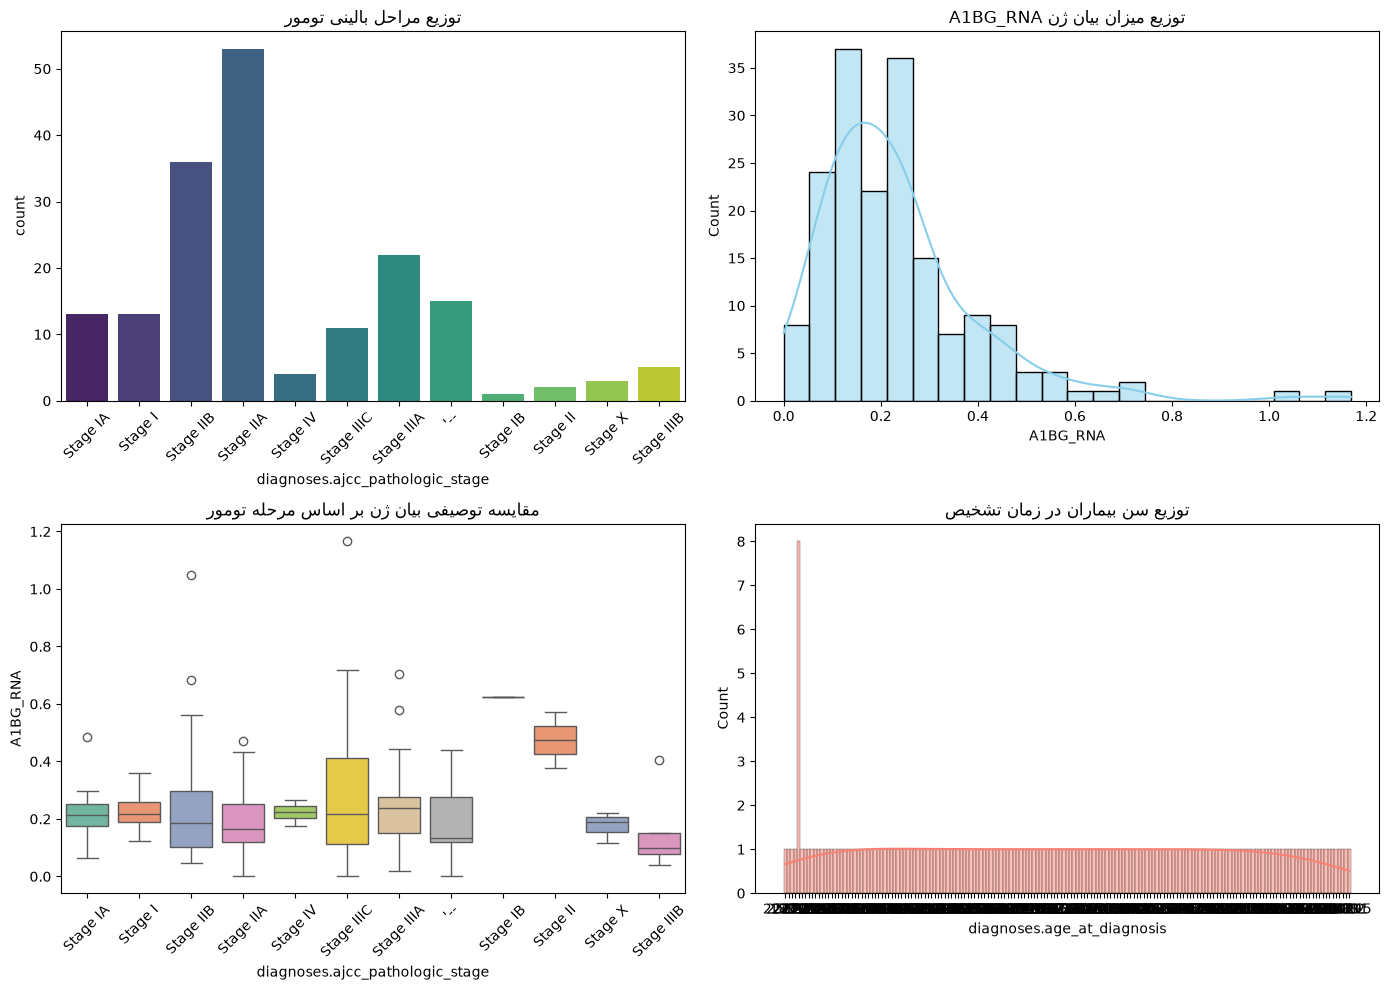

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# ۱. ممیزی مقادیر گمشده متغیرهای اصلی
cols_of_interest = ['diagnoses.ajcc_pathologic_stage', 'diagnoses.age_at_diagnosis', 'A1BG_RNA']
print("بررسی مقادیر گمشده:\n", final_df[cols_of_interest].isnull().sum())

# پاک‌سازی موقت ردیف‌های بدون مرحله بالینی برای رسم نمودار دقیق‌تر
plot_df = final_df.dropna(subset=['diagnoses.ajcc_pathologic_stage', 'A1BG_RNA'])

# ۲. آمار توصیفی برای متغیر کمی پیوسته (ژن)
print("\nآمار توصیفی بیان ژن (A1BG_RNA):")
print(plot_df['A1BG_RNA'].describe())

# ۳. تولید ۴ نمودار معنادار
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# نمودار اول: جدول فراوانی و توزیع مراحل بالینی
sns.countplot(data=plot_df, x='diagnoses.ajcc_pathologic_stage', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('توزیع مراحل بالینی تومور')
axes[0, 0].tick_params(axis='x', rotation=45)

# نمودار دوم: توزیع تجربی بیان ژن
sns.histplot(data=plot_df, x='A1BG_RNA', kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('توزیع میزان بیان ژن A1BG_RNA')

# نمودار سوم: مقایسه توصیفی اولیه (تسک ۹) - بیان ژن در مراحل مختلف
sns.boxplot(data=plot_df, x='diagnoses.ajcc_pathologic_stage', y='A1BG_RNA', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('مقایسه توصیفی بیان ژن بر اساس مرحله تومور')
axes[1, 0].tick_params(axis='x', rotation=45)

# نمودار چهارم: توزیع سن هنگام تشخیص به عنوان یک متغیر بالینی کلیدی
sns.histplot(data=plot_df, x='diagnoses.age_at_diagnosis', kde=True, ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('توزیع سن بیماران در زمان تشخیص')

plt.tight_layout()
plt.show()